# 2.4 — Workshop: a help-desk assistant
**Session 2.4 · Lab · part 1 of the reference app**

What we'll do: build an assistant for the Northgate Logistics IT help desk. We write its system
prompt and examples, make it return checked JSON, test it on 15 questions, then make the repeated
part of every request cheaper with prompt caching.

## What we're building
Across the labs we build one app: an IT help-desk assistant for Northgate Logistics. The parts are numbered
in the order we build them. Today is part **1 · Prompt & JSON**: the system prompt, examples, and a
reply in a fixed format that we check.

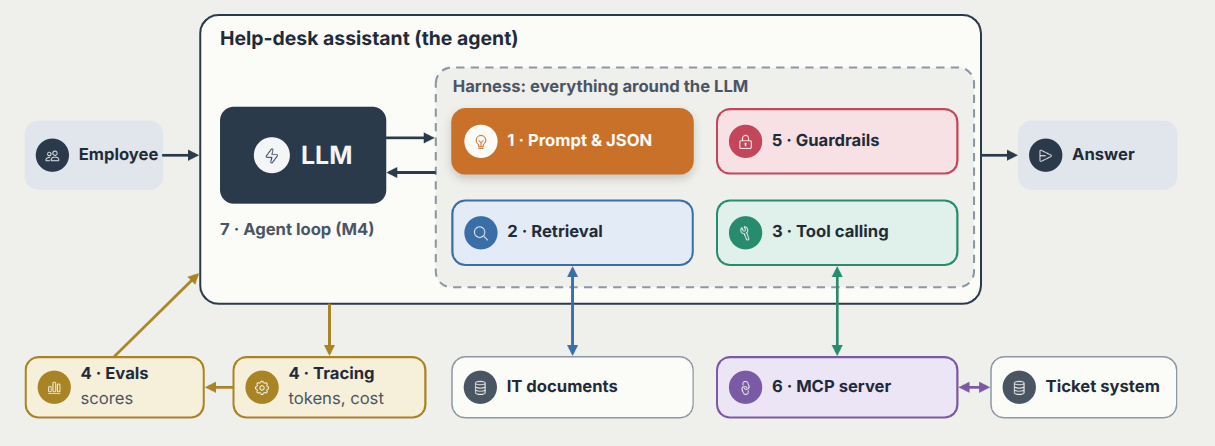

In [ ]:
# @title Setup: install the kit and connect to Claude { display-mode: "form" }
KIT_URL = "git+https://github.com/fastbatchai/helpdesk-assistant.git"

import importlib, importlib.util, shutil, subprocess, sys

INSTALL = (
    ["uv", "pip", "install", "--python", sys.executable, "-q"]
    if shutil.which("uv")
    else [sys.executable, "-m", "pip", "install", "-q"]
)
if importlib.util.find_spec("helpdesk_kit") is None:
    subprocess.check_call([*INSTALL, KIT_URL])
    importlib.invalidate_caches()

import html
import json
import re
from typing import Literal

import pandas as pd
from IPython.display import HTML, display
from pydantic import BaseModel, Field, ValidationError

from helpdesk_kit.evals import (
    load_eval_set,
    plot_pass_rates,
    results_table,
    run_eval,
    score,
)
from helpdesk_kit.llm import chat, extract_json, get_client

pd.set_option("display.max_colwidth", None)
get_client()

INK, SOFT_INK, BLUE, ORANGE, GREY = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#898781"
BOX = "margin:8px 0;padding:10px 14px;background:#fff;border:1px solid #e1e0d9;border-radius:6px"


def badge(text, colour):
    return (
        f'<span style="display:inline-block;margin:6px 6px 0 0;padding:2px 8px;border-radius:10px;'
        f'background:{colour};color:#fff;font-size:12px;font-weight:600">{html.escape(text)}</span>'
    )


def show_reply(question, reply):
    """A checked JSON reply: the answer, then its category, confidence and needs-human as badges."""
    needs_human = badge("needs a human", ORANGE) if reply.needs_human else badge("no human needed", GREY)
    display(HTML(
        f'<div style="{BOX};border-left:3px solid {BLUE}">'
        f'<div style="color:{SOFT_INK};font-weight:600;margin-bottom:4px">{html.escape(question)}</div>'
        f'<div style="color:{INK};white-space:pre-wrap">{html.escape(reply.answer)}</div>'
        f'{badge(reply.category, BLUE)}{badge(f"confidence {reply.confidence:.0%}", SOFT_INK)}{needs_human}</div>'
    ))


def show_text(title, text):
    """A long text (such as a full system prompt) in a scrollable box."""
    display(HTML(
        f'<div style="{BOX}"><div style="color:{SOFT_INK};font-weight:600;margin-bottom:6px">{html.escape(title)}</div>'
        f'<div style="color:{INK};white-space:pre-wrap;font-family:monospace;font-size:13px;'
        f'max-height:320px;overflow-y:auto">{html.escape(text)}</div></div>'
    ))


def show_note(text, colour=SOFT_INK):
    """A one-line note, such as a failed attempt."""
    display(HTML(f'<div style="margin:4px 0;color:{colour};font-weight:600">{html.escape(text)}</div>'))


def show_rows(title, rows, colour=BLUE):
    """A small table of (label, value) rows, with a coloured edge."""
    body = "".join(
        f'<tr><td style="padding:4px 16px 4px 0;color:{SOFT_INK}">{html.escape(str(label))}</td>'
        f'<td style="padding:4px 0;color:{INK};font-weight:600">{html.escape(str(value))}</td></tr>'
        for label, value in rows
    )
    display(HTML(
        f'<div style="{BOX};border-left:3px solid {colour}">'
        f'<div style="color:{INK};font-weight:600;margin-bottom:4px">{html.escape(title)}</div>'
        f'<table style="border-collapse:collapse">{body}</table></div>'
    ))


print("Ready.")

Ready.


In [ ]:
# @title Answer caching { display-mode: "form" }
# @markdown When this is on, a request that is exactly the same as one already sent gets the saved answer
# @markdown back. Untick it (and run this step) to get fresh answers from Claude.
REPLAY = True  # @param {type:"boolean"}

import hashlib
import json
import os

import anthropic
from anthropic.resources.messages import Messages

REPLAY_DIR = "/content/claude_replay" if os.path.isdir("/content") else os.path.expanduser("~/claude_replay")
os.makedirs(REPLAY_DIR, exist_ok=True)
if not hasattr(Messages, "live_create"):
    Messages.live_create = Messages.create  # The real call, kept so we can switch back.
replay_count = {"saved answers reused": 0, "new calls": 0}


def replay_create(self, **request):
    """Every call to Claude comes through here: reuse a saved answer, or call Claude and save the answer."""
    # The connection type is part of the key, so a simulated outage never gets a saved answer.
    connection = type(getattr(getattr(self._client, "_client", None), "_transport", None)).__name__
    key = hashlib.sha256(json.dumps([connection, request], sort_keys=True, default=str).encode()).hexdigest()
    path = os.path.join(REPLAY_DIR, f"{key}.json")
    if os.path.exists(path):
        replay_count["saved answers reused"] += 1
        with open(path) as file:
            return anthropic.types.Message.model_validate_json(file.read())
    response = Messages.live_create(self, **request)
    if isinstance(response, anthropic.types.Message):  # Streamed replies aren't saved.
        with open(path, "w") as file:
            file.write(response.model_dump_json())
    replay_count["new calls"] += 1
    return response


Messages.create = replay_create if REPLAY else Messages.live_create
saved = len(os.listdir(REPLAY_DIR))
print(f"Saved answers {'on' if REPLAY else 'off'}. {saved} saved so far in {REPLAY_DIR}.")

Saved answers on. 6 saved so far in /content/claude_replay.


## 1. Write a system prompt
We start from a weak prompt. Pick one of the three questions (🎲 picks one of them at random), or type your
own, and run the step.
**Watch for:** what the weak prompt gets wrong.

In [ ]:
# @title Try a system prompt { display-mode: "form" }
SYSTEM_PROMPT_TO_TRY = "You are a helpful assistant. Answer IT questions."  # @param {type:"string"}
QUESTION = "How do I reset my password?"  # @param ["How do I reset my password?", "What's the best pizza place near the Rotterdam office?", "I clicked a link in a strange email and typed in my password. What now?", "🎲 random question"] {allow-input: true}

import random

TRY_QUESTIONS = [
    "How do I reset my password?",
    "What's the best pizza place near the Rotterdam office?",
    "I clicked a link in a strange email and typed in my password. What now?",
]


def with_bold(text):
    """The text, safe to show as HTML, with **bold** shown in bold."""
    return re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", html.escape(text))


def bubble(text, mine, label="", caption=""):
    """A chat bubble: the question on the right in blue, the answer on the left in white."""
    side = "margin-left:auto;background:#eaf2fc;border:1px solid #2a78d6" if mine else "background:#fff;border:1px solid #e1e0d9"
    label_html = f'<div style="font-size:12px;font-weight:600;color:{SOFT_INK};margin-bottom:4px">{html.escape(label)}</div>' if label else ""
    caption_html = f'<div style="font-size:11px;color:{SOFT_INK};margin-top:6px">{html.escape(caption)}</div>' if caption else ""
    return (f'<div style="display:flex;margin:6px 0"><div style="{side};border-radius:10px;padding:8px 12px;'
            f'max-width:75%;white-space:pre-wrap;color:{INK}">{label_html}{with_bold(text)}{caption_html}</div></div>')


def ask_and_show(system, question, prompt_title):
    """Ask one question with this system prompt, and show it as a short chat."""
    if question.startswith("🎲"):
        question = random.choice(TRY_QUESTIONS)
    reply = chat(question, system=system, max_tokens=4000)
    caption = f"{reply.usage.input_tokens} tokens in · {reply.usage.output_tokens} out · {reply.seconds:.1f} s"
    display(HTML(
        f'<div style="font-size:12px;color:{SOFT_INK};margin-bottom:4px"><b>{prompt_title}:</b> '
        f'{html.escape(system[:300])}{"…" if len(system) > 300 else ""}</div>'
        + bubble(question, mine=True)
        + bubble(reply.text, mine=False, label="Assistant", caption=caption)
    ))
    if reply.stop_reason == "max_tokens":
        show_note("This answer was cut off: it reached the length limit.", ORANGE)


ask_and_show(SYSTEM_PROMPT_TO_TRY, QUESTION, "System prompt")

In [ ]:
# @title Write our prompt { display-mode: "form" }
# @markdown **Role:** who is it, and who does it serve?
ROLE = ""  # @param {type:"string"}
# @markdown **Scope:** what will it help with, and what won't it?
SCOPE = ""  # @param {type:"string"}
# @markdown **Tone:** how should it sound?
TONE = ""  # @param {type:"string"}
# @markdown **A way out:** what should it do when it doesn't know, or when a person is needed?
WAY_OUT = ""  # @param {type:"string"}
USE_OUR_EXAMPLE = False  # @param {type:"boolean"}

OUR_EXAMPLE = """You are the IT help-desk assistant for Northgate Logistics, a company of about
1,200 employees with offices in Rotterdam, Hamburg and Leeds. You help employees with IT questions.

Scope: accounts and passwords, VPN and Wi-Fi, laptops and printers, software, email and calendars,
Microsoft Teams, shared drives, and IT security. Politely decline anything else, and point to the
right team if you know it: HR for pay and contracts, Facilities for badges and buildings.

Tone: friendly, plain and brief. Give numbered steps when there are steps to follow.

When you don't know: say so. Never invent a policy, number, name or link. If the question is too
vague to answer, ask one clarifying question. Hand over to a human engineer for suspected security
incidents, outages, and anything that changes someone's access."""

PARTS = {"Role": ROLE, "Scope": SCOPE, "Tone": TONE, "A way out": WAY_OUT}

if USE_OUR_EXAMPLE or not any(text.strip() for text in PARTS.values()):
    SYSTEM_PROMPT = OUR_EXAMPLE
    display(HTML(
        f'<div style="{BOX};border-left:3px solid {SOFT_INK}"><b>Using our ready-made prompt.</b>'
        f'<div style="white-space:pre-wrap;margin-top:6px;color:{INK}">{html.escape(OUR_EXAMPLE)}</div></div>'
    ))
else:
    SYSTEM_PROMPT = "\n\n".join(
        text.strip() if name == "Role" else f"{name}: {text.strip()}"
        for name, text in PARTS.items() if text.strip()
    )
    rows = "".join(
        f'<tr><td style="padding:6px 14px 6px 0;color:{SOFT_INK};font-weight:600;vertical-align:top">{name}</td>'
        + (f'<td style="padding:6px 0;color:{INK}">{html.escape(text.strip())}</td>' if text.strip()
           else '<td style="padding:6px 0;color:#eb6834;font-weight:600">not written yet</td>')
        + "</tr>"
        for name, text in PARTS.items()
    )
    display(HTML(f'<div style="{BOX};border-left:3px solid {BLUE}"><b>Our prompt</b>'
                 f'<table style="border-collapse:collapse;margin-top:6px">{rows}</table></div>'))

In [ ]:
# @title Try our prompt { display-mode: "form" }
QUESTION = "How do I reset my password?"  # @param ["How do I reset my password?", "What's the best pizza place near the Rotterdam office?", "I clicked a link in a strange email and typed in my password. What now?", "🎲 random question"] {allow-input: true}

ask_and_show(SYSTEM_PROMPT, QUESTION, "Our system prompt")

## 2. Add 3 examples and a JSON output format
A program can't read a friendly paragraph, so the assistant also returns its answer as JSON, with
labels a program can act on: a category, how confident it is, and whether a person must take over.
This is the format, with the categories it may choose from.

In [ ]:
# @title The reply format { display-mode: "form" }
Category = Literal[
    "network",
    "account_access",
    "hardware",
    "software",
    "email_calendar",
    "security",
    "policy",
    "out_of_scope",
    "unclear",
]


class HelpdeskReply(BaseModel):
    answer: str = Field(min_length=1, description="The reply shown to the employee.")
    category: Category
    confidence: float = Field(
        ge=0, le=1, description="From 0 (guessing) to 1 (certain)."
    )
    needs_human: bool = Field(description="True if an engineer must take over.")


show_rows(
    "Every reply has these four fields",
    [
        ("answer", "the reply shown to the employee"),
        ("category", ", ".join(Category.__args__)),
        ("confidence", "a number from 0 (guessing) to 1 (certain)"),
        ("needs_human", "true if an engineer must take over"),
    ],
)

answer,the reply shown to the employee
category,"network, account_access, hardware, software, email_calendar, security, policy, out_of_scope, unclear"
confidence,a number from 0 (guessing) to 1 (certain)
needs_human,true if an engineer must take over


We write three examples that show the behaviour we want, each in a different situation: a normal
question, one that's out of scope, and one that needs a human. Each example is a question and the reply we
want, in the format above.

In [ ]:
# @title Write our three examples { display-mode: "form" }
# @markdown **Example 1: a normal question**
QUESTION_1 = "Where do I find the Teams settings for my microphone?"  # @param {type:"string"}
ANSWER_1 = "In Teams, open Settings, then Devices, and choose your microphone there. You can make a test call from the same menu."  # @param {type:"string"}
CATEGORY_1 = "software"  # @param ["network", "account_access", "hardware", "software", "email_calendar", "security", "policy", "out_of_scope", "unclear"]
CONFIDENCE_1 = 0.9  # @param {type:"slider", min:0, max:1, step:0.05}
NEEDS_HUMAN_1 = False  # @param {type:"boolean"}
# @markdown **Example 2: out of scope**
QUESTION_2 = "When will my pay rise come through?"  # @param {type:"string"}
ANSWER_2 = "That's one for HR, as the IT help desk doesn't handle pay. Your HR contact can help."  # @param {type:"string"}
CATEGORY_2 = "out_of_scope"  # @param ["network", "account_access", "hardware", "software", "email_calendar", "security", "policy", "out_of_scope", "unclear"]
CONFIDENCE_2 = 0.95  # @param {type:"slider", min:0, max:1, step:0.05}
NEEDS_HUMAN_2 = False  # @param {type:"boolean"}
# @markdown **Example 3: needs a human**
QUESTION_3 = "My laptop was stolen from my car an hour ago."  # @param {type:"string"}
ANSWER_3 = "Please phone the help desk now, so an engineer can lock the laptop remotely. Stolen devices must be handled by a person, straight away."  # @param {type:"string"}
CATEGORY_3 = "security"  # @param ["network", "account_access", "hardware", "software", "email_calendar", "security", "policy", "out_of_scope", "unclear"]
CONFIDENCE_3 = 0.9  # @param {type:"slider", min:0, max:1, step:0.05}
NEEDS_HUMAN_3 = True  # @param {type:"boolean"}

SITUATIONS = ["a normal question", "out of scope", "needs a human"]
FILLED_IN = [
    (QUESTION_1, ANSWER_1, CATEGORY_1, CONFIDENCE_1, NEEDS_HUMAN_1),
    (QUESTION_2, ANSWER_2, CATEGORY_2, CONFIDENCE_2, NEEDS_HUMAN_2),
    (QUESTION_3, ANSWER_3, CATEGORY_3, CONFIDENCE_3, NEEDS_HUMAN_3),
]

examples = []
for situation, (question, answer, category, confidence, needs_human) in zip(SITUATIONS, FILLED_IN):
    if not question.strip() or not answer.strip():
        show_note(f"The example for {situation} needs a question and an answer.", ORANGE)
        continue
    reply = HelpdeskReply(answer=answer, category=category, confidence=confidence, needs_human=needs_human)
    examples.append((question, reply))
    show_reply(f"Example: {situation} · {question}", reply)

# The examples as the assistant receives them: a question, then the reply in the JSON format.
EXAMPLES = "\n\n".join(
    f"<example>\nQuestion: {question}\nReply: {reply.model_dump_json()}\n</example>" for question, reply in examples
)

The prompt, the examples and the format rules go together into one system prompt. This is everything
the assistant receives before each question.

In [ ]:
# @title Put the system prompt together { display-mode: "form" }
def build_prompt(system, examples=""):
    """Combine the prompt, the examples and the output rules into one system prompt."""
    schema = json.dumps(HelpdeskReply.model_json_schema())
    return f"""{system}

{examples}

Return only a JSON object that matches this schema, with no other text:
{schema}"""


STRUCTURED_PROMPT = build_prompt(SYSTEM_PROMPT, EXAMPLES)
show_text("The full system prompt", STRUCTURED_PROMPT)

### Catch a bad reply
Models sometimes break the format. Every reply goes through **Pydantic**, a tool that checks the JSON
against the format and names every field that's wrong.

In [ ]:
# A bad reply: a category that doesn't exist, the confidence in words, and a field missing.
BAD_REPLY = '{"answer": "Try rebooting it.", "category": "computers", "confidence": "very high"}'

In [ ]:
# @title Check the bad reply { display-mode: "form" }
try:
    HelpdeskReply.model_validate_json(BAD_REPLY)
except ValidationError as error:
    show_rows(
        f"The check found {error.error_count()} problems",
        [(".".join(str(part) for part in problem["loc"]), problem["msg"]) for problem in error.errors()],
        colour=ORANGE,
    )

category,"Input should be 'network', 'account_access', 'hardware', 'software', 'email_calendar', 'security', 'policy', 'out_of_scope' or 'unclear'"
confidence,"Input should be a valid number, unable to parse string as a number"
needs_human,Field required


### A retry that fixes it
When the check fails, we send the problems back to the model and ask it to correct its reply, up to
three tries. We start from the bad reply above, so the retry always shows.

In [ ]:
# @title Retry until the reply passes the check { display-mode: "form" }
def ask(question, system=None, first_reply=None, max_attempts=3):
    """Ask, check the reply, and send the problems back until it passes (or we run out of tries)."""
    system = system or STRUCTURED_PROMPT
    messages = [{"role": "user", "content": question}]
    text = first_reply

    for attempt in range(1, max_attempts + 1):
        if text is None:
            text = chat(messages, system=system, max_tokens=4000).text
        try:
            return HelpdeskReply.model_validate_json(extract_json(text))
        except ValidationError as error:
            show_note(
                f"Attempt {attempt}: the reply failed the check ({error.error_count()} problems). "
                "Sent back to the model.",
                ORANGE,
            )
            messages.append({"role": "assistant", "content": text})
            messages.append(
                {
                    "role": "user",
                    "content": f"That reply failed validation:\n{error}\n\nReturn only the corrected JSON.",
                }
            )
            text = None

    raise ValueError(f"No valid reply after {max_attempts} attempts.")


show_reply("My laptop won't turn on.", ask("My laptop won't turn on.", first_reply=BAD_REPLY))

## 3. Run the 15 test questions
A mix of in-scope, out-of-scope, ambiguous and needs-a-human questions. For each one, the table
shows the assistant's answer and its labels next to the ones we expect.

In [ ]:
# @title Run the 15 test questions { display-mode: "form" }
cases = load_eval_set()
before = run_eval(lambda question: ask(question, system=STRUCTURED_PROMPT), cases)

display(results_table(before))

,id,type,question,answer,category,expected_category,needs_human,expected_needs_human,confidence,error
0,q01,in_scope,How do I reset my password?,"Happy to help. Which password do you need to reset: your Windows/laptop login, email and Microsoft 365, or something else like VPN? And can you still sign in, or are you locked out? I don't have a verified self-service reset link to hand, so I don't want to point you to the wrong one. If you're locked out, an engineer will need to reset it for you.",account_access,account_access,False,False,0.50,None
1,q02,in_scope,What hours is the IT help desk open?,"I don't have the help desk's opening hours, and I don't want to guess. Your intranet or the signature in a past help desk email should list them. If something is urgent, such as a suspected security problem or an outage, contact the help desk directly.",policy,policy,False,False,0.60,None
2,q03,in_scope,How soon should I expect a first response to a P2 ticket?,"I don't have the response-time targets for P2 tickets, and I don't want to guess a number. The ticket confirmation you received or the IT service catalogue should list the SLA. If you can't find it, ask the help desk directly. If your issue is urgent or affecting several people, let the help desk know so an engineer can look at it.",policy,policy,False,False,0.85,None
3,q04,in_scope,My VPN shows error NGL-809. What does it mean?,"I don't recognise the error code NGL-809, so I can't say for sure what it means. These general steps often clear VPN problems:\n1. Check that your internet works without the VPN, for example by opening a website.\n2. Close the VPN app completely, then open it and try again.\n3. Restart your laptop and reconnect.\n\nIf the error is still there, please contact the help desk and give them the code NGL-809, a screenshot of the message, and the time it happened. An engineer can then look it up. If other colleagues have the same error, tell them, as it could be an outage.",network,network,False,False,0.30,None
4,q05,in_scope,How often does my laptop get replaced?,"I don't know Northgate's laptop replacement cycle, and I don't want to guess. Your line manager or the IT help desk can confirm what applies to you. If your laptop is slow or faulty now, tell me what's happening and I can help troubleshoot.",policy,hardware,False,False,0.80,None
5,q06,in_scope,How many failed sign-ins before my account locks?,"I don't know the exact number of failed sign-ins that triggers a lockout at Northgate, and I don't want to guess. If you're worried about being locked out, stop trying and use the self-service password reset if you have it set up. If your account is already locked, contact the help desk so an engineer can unlock it.",policy,account_access,False,False,0.25,None
6,q07,in_scope,How often do I have to change my password?,"I don't have Northgate's password change policy, so I can't give you a reliable answer. Please check the IT security policy or ask the help desk to confirm how often passwords must be changed. If you'd like to change your password now, tell me and I'll walk you through it.",policy,account_access,False,False,0.30,None
7,q08,in_scope,I got an email that looks like phishing but I didn't click anything. What should I do?,"Good call not clicking. Here's what to do:\n1. Don't click any links, open attachments, or reply.\n2. Don't forward it to colleagues, as that can spread the risk.\n3. Report it to the IT help desk so an engineer can check it and block the sender if needed. If you have a 'Report phishing' button in Outlook, you can use that too, but I can't confirm which reporting method Northgate prefers.\n4. Once an engineer has told you it's been dealt with, delete the email.\n\nIf you do end up clicking a link or opening an attachment, or entering your password anywhere, tell the help desk straight away.",security,security,True,False,0.80,None
8,q09,out_of_scope,What's the best pizza place near the Rotterdam office?,"Sorry, restaurant recommendat

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


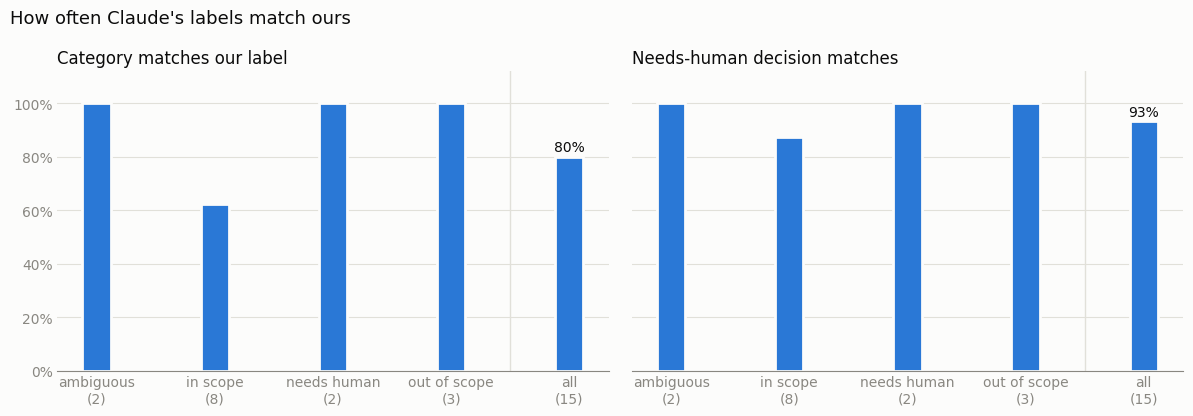

In [ ]:
# @title How often the labels match ours { display-mode: "form" }
plot_pass_rates({"prompt + examples": score(before)}, "How often Claude's labels match ours")

## 4. Prompt caching: pay less for the part that never changes
The 15 questions we just ran each sent the **same** system prompt, examples and format again; only
the question changed. Claude can **cache** the part that stays the same:
1. We mark where the stable part ends.
2. The first request **writes** that part to the cache. It costs a little more than normal input (1.25×).
3. For the next 5 minutes, every request that **starts with exactly the same text** reads it from the
   cache instead: about 20 times cheaper on Sonnet 5.5, and faster. Each read restarts the 5 minutes.

Two rules follow from this:
- The cached part must be **identical**, character for character. Change one character (a date, a
  time) and it's a miss.
- It has to come **first**. That's why the question goes after it, not inside it.

On these models the cached part must be at least 512 tokens; a shorter prompt simply isn't cached,
with no error.

In [ ]:
# @title Ask three questions with the cache { display-mode: "form" }
# The system prompt as a list of blocks, so we can put the cache marker on it.
CACHED_SYSTEM = [
    {
        "type": "text",
        "text": STRUCTURED_PROMPT,
        "cache_control": {"type": "ephemeral"},  # Cache everything up to here, for 5 minutes.
    }
]

MODEL = "claude-sonnet-5-5"
# Sonnet 5.5 prices in dollars per million tokens.
PRICE = {"input": 2.00, "cache write": 2.50, "cache read": 0.10, "output": 10.00}


def ask_with_cache(question):
    """Ask one question with the cached system prompt, and report what the cache did."""
    reply = chat(question, system=CACHED_SYSTEM, model=MODEL, max_tokens=4000)
    usage = reply.usage
    written = usage.cache_creation_input_tokens or 0  # These two can be empty: count that as 0.
    read = usage.cache_read_input_tokens or 0
    cost = (
        usage.input_tokens * PRICE["input"]
        + written * PRICE["cache write"]
        + read * PRICE["cache read"]
        + usage.output_tokens * PRICE["output"]
    ) / 1_000_000
    return {
        "question": question,
        "written to cache": written,
        "read from cache": read,
        "not cached": usage.input_tokens,
        "cost": cost,
        "seconds": round(reply.seconds, 1),
    }


QUESTIONS = [
    "How do I connect to the office Wi-Fi?",
    "My Outlook keeps asking for my password.",
    "Can I install Spotify on my work laptop?",
]
cache_runs = pd.DataFrame([ask_with_cache(question) for question in QUESTIONS])
display(cache_runs.style.format({"cost": "${:.5f}", "seconds": "{:.1f}"}).hide(axis="index"))

,question,written to cache,read from cache,not cached,cost,seconds
0,How do I connect to the office Wi-Fi?,864,0,22,$0.00562,3.300000
1,My Outlook keeps asking for my password.,0,864,20,$0.00314,3.000000
2,Can I install Spotify on my work laptop?,0,864,21,$0.00521,5.000000


## What we built
This is part 1 of the reference app: a system prompt, examples, checked JSON output, a retry,
and a test set. In Module 3 it gets retrieval, tools, evals and guardrails.